# 11 · Supplier Financial Risk for Procurement

| | |
|---|---|
| **Question** | Which of a client's suppliers could fail financially, how much spend is exposed, and what should procurement do about it? |
| **Inputs** | `gold.mart_supplier_health` (FY2018 10-K filings of US public companies, SEC) |
| **Outputs** | Supplier risk tiers, a procurement risk report for a client, `data/app/supplier_scores.parquet`, `data/app/procurement_spend.parquet` |
| **Skills shown** | Financial ratio analysis, Altman Z'', validating a score without default labels, composite risk tiers, spend analytics, concentration (HHI), turning analytics into procurement actions |

### Why a lender cares about procurement

Meridian's corporate clients ask the same question a credit officer asks, about their suppliers: *will this counterparty still be there next year?* A supplier failure stops production lines, and the cheapest supplier is often the most fragile. Meridian answers with the same risk engine it uses for lending, and earns revenue from it: suppliers in the "grey" zone are natural candidates for **supplier finance** (early payment of their invoices, funded by Meridian).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from meridian import config, viz
from meridian.db import connect

viz.set_style()
con = connect()
APP = config.DATA_DIR / "app"
REPORTS = config.PROJECT_ROOT / "reports"
universe = con.execute("""
    select * from gold.mart_supplier_health
    where is_procurement_relevant and altman_zone <> 'Unscored' and revenue >= 50e6
""").df()
print(f"Scored supplier universe: {len(universe):,} US public companies with revenue of USD 50M or more, "
      f"in {universe.sector_name.nunique()} procurement-relevant sectors")

Scored supplier universe: 1,351 US public companies with revenue of USD 50M or more, in 7 procurement-relevant sectors


Financial companies (banks, insurers, real estate) and retailers are excluded: they are rarely industrial suppliers, and Altman Z'' is not designed for financial balance sheets. Companies below USD 50M revenue are excluded because many are pre-revenue biotech or shell companies, not realistic suppliers.

## 1. The score: Altman Z''

$$Z'' = 6.56\,\frac{\text{Working capital}}{\text{Total assets}} + 3.26\,\frac{\text{Retained earnings}}{\text{Total assets}} + 6.72\,\frac{\text{EBIT}}{\text{Total assets}} + 1.05\,\frac{\text{Book equity}}{\text{Total liabilities}}$$

Altman's 1995 Z'' variant is used instead of the original 1968 Z-score because it does not need a stock price (many suppliers are private) and works for non-manufacturers. Zones: **safe** above 2.60, **grey** 1.10 to 2.60, **distress** below 1.10. All ratios are computed in SQL in `mart_supplier_health.sql`.

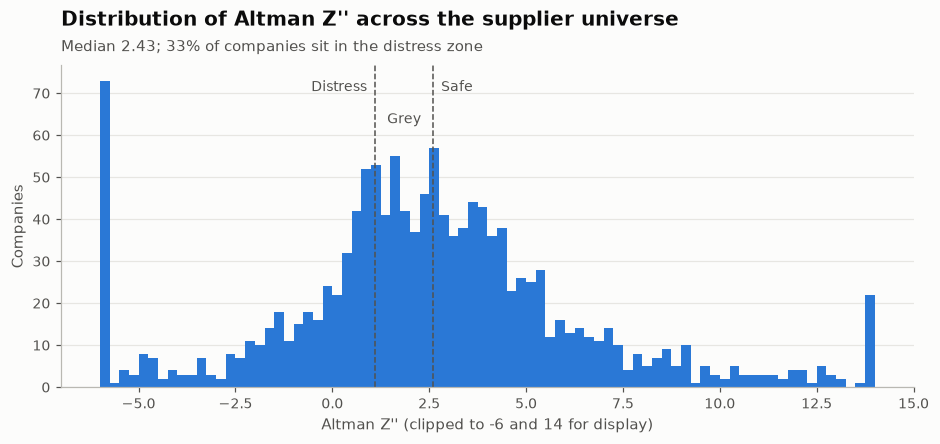

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.8))
z = universe.altman_z_double_prime.clip(-6, 14)
ax.hist(z, bins=80, color=viz.BLUE)
top = ax.get_ylim()[1]
for x, label, ha in [(1.10, "Distress  ", "right"), (2.60, "  Safe", "left")]:
    ax.axvline(x, color=viz.INK_2, lw=1, ls="--")
    ax.text(x, top * 0.92, label, fontsize=9, color=viz.INK_2, ha=ha)
ax.text(1.85, top * 0.82, "Grey", fontsize=9, color=viz.INK_2, ha="center")
ax.set_xlabel("Altman Z'' (clipped to -6 and 14 for display)")
ax.set_ylabel("Companies")
ax.set_title("Distribution of Altman Z'' across the supplier universe")
viz.subtitle(ax, f"Median {universe.altman_z_double_prime.median():.2f}; "
             f"{(universe.altman_zone == 'Distress').mean():.0%} of companies sit in the distress zone")
plt.show()

## 2. Does the score mean anything? Validation without default labels

The SEC data contains no record of which companies later failed, so the score cannot be backtested against defaults. It can be validated against **independent signs of financial stress** that are *not* inputs to Z'':

| Signal | Why it signals stress |
|---|---|
| Negative operating cash flow | The business consumes cash instead of generating it |
| Interest coverage below 1.5 | Operating profit barely covers interest |
| Net loss | The company lost money in the year |
| Current ratio below 1 | Short-term debts exceed short-term assets |

If Z'' is meaningful, companies in the distress zone should show these signals far more often.

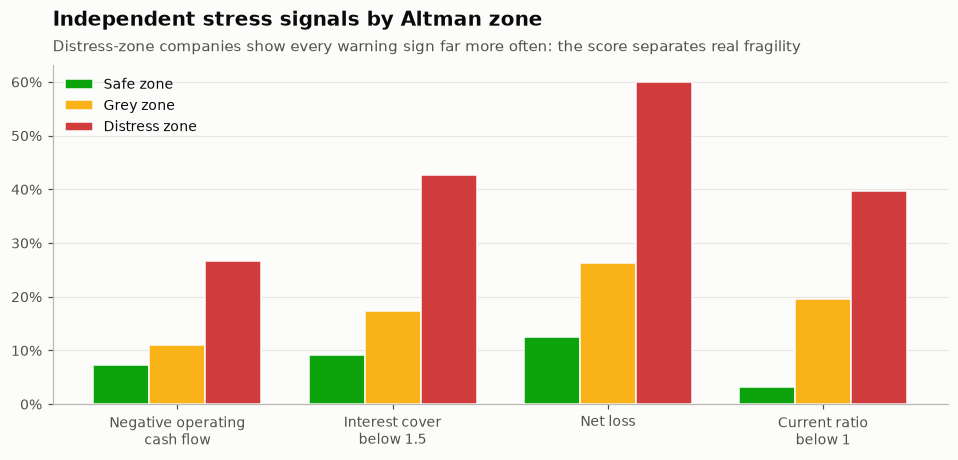

,flag_negative_cash_flow,flag_low_interest_cover,flag_net_loss,flag_current_ratio_below_1,red_flags
altman_zone,,,,,
Safe,7.3%,9.1%,12.6%,3.2%,0.32
Grey,11.0%,17.4%,26.2%,19.5%,0.74
Distress,26.8%,42.6%,60.1%,39.7%,1.69


In [3]:
universe["flag_negative_cash_flow"] = (universe.operating_cash_flow < 0).astype(int)
universe["flag_low_interest_cover"] = (universe.interest_coverage < 1.5).astype(int)
universe["flag_net_loss"] = (universe.net_income < 0).astype(int)
universe["flag_current_ratio_below_1"] = (universe.current_ratio < 1).astype(int)
FLAGS = ["flag_negative_cash_flow", "flag_low_interest_cover", "flag_net_loss", "flag_current_ratio_below_1"]
universe["red_flags"] = universe[FLAGS].sum(axis=1)

zones = ["Safe", "Grey", "Distress"]
val = universe.groupby("altman_zone")[FLAGS + ["red_flags"]].mean().loc[zones]
fig, ax = plt.subplots(figsize=(10.5, 4))
x = np.arange(len(FLAGS))
for i, (zone, color) in enumerate(zip(zones, [viz.GOOD, viz.WARNING, viz.CRITICAL])):
    ax.bar(x + (i - 1) * 0.26, val.loc[zone, FLAGS], 0.26, color=color, label=f"{zone} zone", edgecolor=viz.SURFACE, linewidth=1)
ax.set_xticks(x, ["Negative operating\ncash flow", "Interest cover\nbelow 1.5", "Net loss", "Current ratio\nbelow 1"])
viz.pct(ax)
ax.legend(loc="upper left")
ax.set_title("Independent stress signals by Altman zone")
viz.subtitle(ax, "Distress-zone companies show every warning sign far more often: the score separates real fragility")
plt.show()
val.style.format("{:.1%}", subset=FLAGS).format("{:.2f}", subset=["red_flags"])

**Validated.** Compared with safe-zone companies, distress-zone companies report a net loss about five times as often (60% versus 13%), have interest cover below 1.5 almost five times as often (43% versus 9%), burn operating cash nearly four times as often, and have a current ratio below 1 twelve times as often. The grey zone sits in between on every signal. The score captures real financial fragility.

### Where Z'' is wrong: large companies with finance arms

In [4]:
big = universe.nlargest(8, "revenue")[["company_name", "sector_name", "revenue", "altman_z_double_prime", "altman_zone",
                                       "red_flags", "net_margin", "operating_cash_flow"]]
big.style.format({"revenue": "${:,.0f}", "altman_z_double_prime": "{:.2f}", "net_margin": "{:.1%}",
                  "operating_cash_flow": "${:,.0f}"}).hide(axis="index")

company_name,sector_name,revenue,altman_z_double_prime,altman_zone,red_flags,net_margin,operating_cash_flow
MCKESSON CORP,Wholesale Trade,"$214,319,000,000",1.03,Distress,0,0.0%,"$4,036,000,000"
CHEVRON CORP,Manufacturing,"$166,339,000,000",4.70,Safe,0,8.9%,"$30,618,000,000"
FORD MOTOR CO,Manufacturing,"$160,338,000,000",1.06,Distress,0,nan%,$nan
GENERAL MOTORS CO,Manufacturing,"$147,049,000,000",0.47,Distress,1,5.4%,"$15,256,000,000"
ALPHABET INC.,Services,"$136,819,000,000",8.88,Safe,0,22.5%,"$47,971,000,000"
BOEING CO,Manufacturing,"$101,127,000,000",2.59,Grey,0,10.3%,"$15,322,000,000"
MARATHON PETROLEUM CORP,Manufacturing,"$95,750,000,000",2.03,Grey,0,2.9%,"$6,158,000,000"
COMCAST CORP,"Transportation, Communications and Utilities","$94,507,000,000",1.32,Grey,1,12.4%,"$24,297,000,000"


Three of the largest US companies fall in the distress zone, and none of them was close to failing:

- **General Motors** earned a 5.4% net margin with USD 15 billion of operating cash flow. **Ford** was also profitable in 2018 (its cash-flow tags are missing from the extract, shown as blanks). Both carry **captive finance subsidiaries** (GM Financial, Ford Credit) whose debt funds car loans for customers. That debt drags the equity-to-liabilities ratio down.
- **McKesson**, a pharmaceutical distributor, runs on thin margins and negative working capital by design: it collects from pharmacies faster than it pays manufacturers. Low working capital is a strength of its model, not a weakness.

A procurement analyst would not treat any of them as a likely failure.

**Lesson:** a single ratio-based score needs a second opinion. The risk tier below combines the Altman zone with the independent red flags, so a "distress" score backed by healthy cash flows and profits is treated differently from one backed by losses and cash burn.

## 3. Supplier risk tiers

In [5]:
def tier(row):
    if row.altman_zone == "Distress":
        return "Tier 4 Critical" if row.red_flags >= 2 else "Tier 3 High"
    if row.altman_zone == "Grey" or row.red_flags >= 2:
        return "Tier 2 Watch"
    return "Tier 1 Low"

TIERS = ["Tier 1 Low", "Tier 2 Watch", "Tier 3 High", "Tier 4 Critical"]
TIER_COLORS = dict(zip(TIERS, [viz.GOOD, viz.WARNING, viz.SERIOUS, viz.CRITICAL]))
universe["risk_tier"] = pd.Categorical(universe.apply(tier, axis=1), categories=TIERS, ordered=True)
rules = pd.DataFrame({
    "rule": ["Safe zone and at most 1 red flag", "Grey zone, or safe with 2+ red flags",
             "Distress zone, at most 1 red flag (often leveraged but healthy)", "Distress zone and 2+ red flags"],
    "companies": universe.risk_tier.value_counts().reindex(TIERS).values,
    "procurement_action": ["Standard annual review", "Quarterly monitoring; offer supplier finance",
                           "Confirm with cash-flow review; contingency plan if critical", "Qualify an alternative supplier now; secure inventory"],
}, index=TIERS)
rules

,rule,companies,procurement_action
Tier 1 Low,Safe zone and at most 1 red flag,571,Standard annual review
Tier 2 Watch,"Grey zone, or safe with 2+ red flags",339,Quarterly monitoring; offer supplier finance
Tier 3 High,"Distress zone, at most 1 red flag (often lever...",197,Confirm with cash-flow review; contingency pla...
Tier 4 Critical,Distress zone and 2+ red flags,244,Qualify an alternative supplier now; secure in...


In [6]:
universe.loc[universe.company_name.isin(["FORD MOTOR CO", "GENERAL MOTORS CO", "BOEING CO"]),
             ["company_name", "altman_zone", "red_flags", "risk_tier"]].style.hide(axis="index")

company_name,altman_zone,red_flags,risk_tier
GENERAL MOTORS CO,Distress,1,Tier 3 High
FORD MOTOR CO,Distress,0,Tier 3 High
BOEING CO,Grey,0,Tier 2 Watch


Ford and GM now sit in Tier 3 (distress score, but at most one red flag), which triggers a cash-flow review rather than an alarm. A supplier with a distress score *and* losses *and* cash burn lands in Tier 4.

## 4. A client's procurement risk report

To show the analysis in use, Meridian's corporate client **Atlas Industrial Group** (fictional) shares its supplier list. The spend ledger below is **synthetic**: 350 suppliers drawn from the real scored universe, with annual spend generated to be realistic (log-normal, at most 3% of the supplier's revenue) and a 15% share of single-source suppliers. The supplier financials are real.

In [7]:
rng = np.random.default_rng(2019)
CATEGORY = {"Manufacturing": "Components and materials", "Wholesale Trade": "MRO and distribution",
            "Transportation, Communications and Utilities": "Logistics, telecom and utilities",
            "Services": "Professional and IT services", "Mining": "Raw materials and energy",
            "Construction": "Facilities and construction", "Agriculture, Forestry and Fishing": "Raw materials and energy"}
weights = universe.sector_name.map({"Manufacturing": 3.0, "Wholesale Trade": 3.0, "Services": 1.2,
                                    "Transportation, Communications and Utilities": 1.5, "Mining": 1.0,
                                    "Construction": 2.0, "Agriculture, Forestry and Fishing": 2.0})
pool = universe[universe.revenue.between(50e6, 30e9)]
picked = pool.sample(350, weights=weights.loc[pool.index], random_state=7)
spend = np.minimum(rng.lognormal(mean=np.log(1.2e6), sigma=1.25, size=len(picked)), 0.03 * picked.revenue.values)
ledger = picked[["company_cik", "company_name", "sector_name", "state_code", "revenue", "altman_z_double_prime",
                 "altman_zone", "red_flags", "risk_tier"]].assign(
    category=picked.sector_name.map(CATEGORY), annual_spend=spend.round(-3),
    single_source=rng.random(len(picked)) < np.where(picked.sector_name == "Manufacturing", 0.2, 0.1))
total = ledger.annual_spend.sum()
print(f"Spend under management: ${total / 1e6:,.0f}M across {len(ledger)} suppliers")

Spend under management: $816M across 350 suppliers


In [8]:
by_tier = ledger.groupby("risk_tier", observed=True).agg(suppliers=("company_cik", "size"), spend=("annual_spend", "sum"),
                                                         single_source=("single_source", "sum"))
by_tier["share_of_spend"] = by_tier.spend / total
shares = ledger.annual_spend / total
kpis = pd.Series({
    "Spend under management": f"${total / 1e6:,.0f}M",
    "Suppliers": f"{len(ledger)}",
    "Spend at risk (Tier 3 and 4)": f"${by_tier.loc[['Tier 3 High', 'Tier 4 Critical'], 'spend'].sum() / 1e6:,.0f}M "
                                    f"({by_tier.loc[['Tier 3 High', 'Tier 4 Critical'], 'share_of_spend'].sum():.0%})",
    "Spend with Tier 4 Critical suppliers": f"${by_tier.loc['Tier 4 Critical', 'spend'] / 1e6:,.0f}M "
                                            f"({by_tier.loc['Tier 4 Critical', 'share_of_spend']:.0%})",
    "Single-source suppliers in Tier 3 or 4": f"{int(ledger[ledger.single_source & ledger.risk_tier.isin(TIERS[2:])].shape[0])}",
    "Top-10 supplier share of spend": f"{shares.nlargest(10).sum():.0%}",
    "Supplier concentration (HHI)": f"{(np.square(shares * 100)).sum():,.0f}",
}, name="Atlas Industrial Group")
kpis.to_frame()

,Atlas Industrial Group
Spend under management,$816M
Suppliers,350
Spend at risk (Tier 3 and 4),$229M (28%)
Spend with Tier 4 Critical suppliers,$139M (17%)
Single-source suppliers in Tier 3 or 4,10
Top-10 supplier share of spend,22%
Supplier concentration (HHI),95


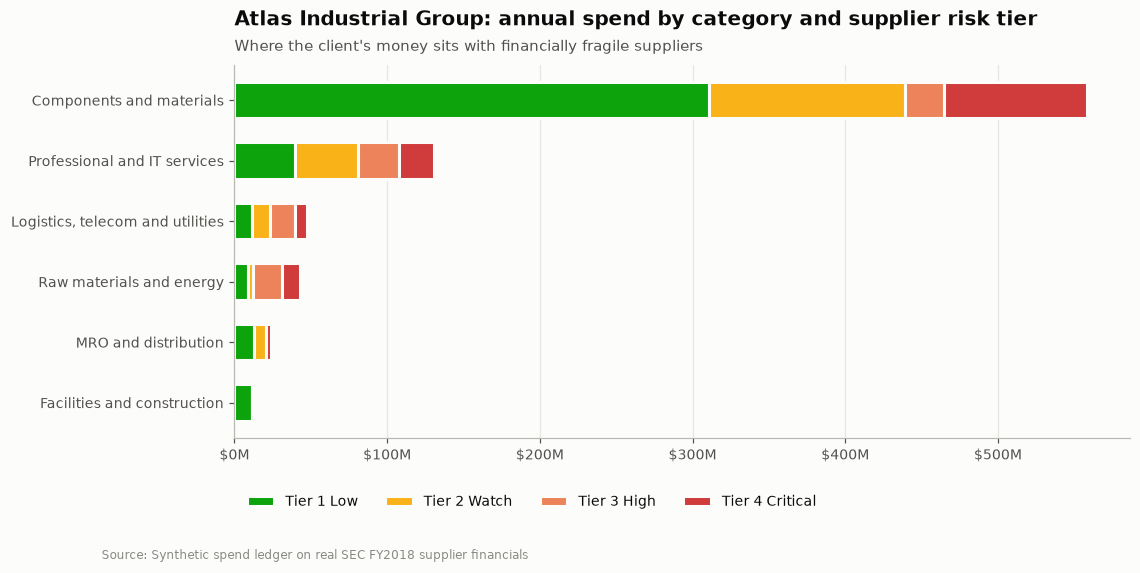

In [9]:
cat = ledger.pivot_table(index="category", columns="risk_tier", values="annual_spend", aggfunc="sum", observed=False).fillna(0)
cat = cat.loc[cat.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10.5, 4.4))
left = np.zeros(len(cat))
for t in TIERS:
    ax.barh(cat.index, cat[t] / 1e6, left=left, color=TIER_COLORS[t], label=t, height=0.6, edgecolor=viz.SURFACE, linewidth=2)
    left += cat[t].values / 1e6
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}M"))
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=4)
ax.set_title("Atlas Industrial Group: annual spend by category and supplier risk tier")
viz.subtitle(ax, "Where the client's money sits with financially fragile suppliers")
viz.source(fig, "Synthetic spend ledger on real SEC FY2018 supplier financials", y=-0.12)
plt.show()

## 5. Action list

The output a procurement director needs is not a score; it is a short list of suppliers to act on this quarter, in priority order: **critical tier, single-source, largest spend first**.

In [10]:
actions = ledger[ledger.risk_tier.isin(["Tier 3 High", "Tier 4 Critical"])].copy()
actions["priority"] = (actions.risk_tier == "Tier 4 Critical").astype(int) * 2 + actions.single_source.astype(int)
actions = actions.sort_values(["priority", "annual_spend"], ascending=False)
actions["recommended_action"] = np.select(
    [(actions.risk_tier == "Tier 4 Critical") & actions.single_source, actions.risk_tier == "Tier 4 Critical", actions.single_source],
    ["Qualify a second source now; build safety stock", "Shift volume to healthier suppliers in the category",
     "Cash-flow review; prepare contingency plan"], "Monitor quarterly")
actions.head(12)[["company_name", "category", "annual_spend", "altman_z_double_prime", "red_flags", "risk_tier",
                  "single_source", "recommended_action"]].style.format(
    {"annual_spend": "${:,.0f}", "altman_z_double_prime": "{:.2f}"}).hide(axis="index")

company_name,category,annual_spend,altman_z_double_prime,red_flags,risk_tier,single_source,recommended_action
LIBBEY INC,Components and materials,"$24,033,000",0.98,2,Tier 4 Critical,True,Qualify a second source now; build safety stock
EP ENERGY CORP,Raw materials and energy,"$5,712,000",-4.59,3,Tier 4 Critical,True,Qualify a second source now; build safety stock
CUENTAS INC.,MRO and distribution,"$2,240,000",-24.52,4,Tier 4 Critical,True,Qualify a second source now; build safety stock
"LILIS ENERGY, INC.",Raw materials and energy,"$2,106,000",-2.59,2,Tier 4 Critical,True,Qualify a second source now; build safety stock
PATTERN ENERGY GROUP INC.,"Logistics, telecom and utilities","$1,584,000",0.01,2,Tier 4 Critical,True,Qualify a second source now; build safety stock
ORCHIDS PAPER PRODUCTS CO /DE,Components and materials,"$526,000",-3.42,4,Tier 4 Critical,True,Qualify a second source now; build safety stock
"FIREEYE, INC.",Components and materials,"$24,928,000",-1.25,2,Tier 4 Critical,False,Shift volume to healthier suppliers in the category
REVLON CONSUMER PRODUCTS CORP,Components and materials,"$5,393,000",-1.76,3,Tier 4 Critical,False,Shift volume to healthier suppliers in the category
SMARTSHEET INC,Professional and IT services,"$5,320,000",0.70,2,Tier 4 Critical,False,Shift volume to healthier suppliers in the category
GOGO INC.,"Logistics, telecom and utilities","$4,828,000",-2.01,3,Tier 4 Critical,False,Shift volume to healthier suppliers in the category


## 6. The revenue opportunity for Meridian: supplier finance

Grey-zone suppliers are healthy enough to keep but often short of working capital. Meridian can pay their invoices early on the client's behalf in exchange for a small discount. The supplier gets cash sooner and becomes more resilient; the client keeps its payment terms; Meridian earns the discount on a low-risk, short-term asset backed by an investment-grade buyer.

In [11]:
DISCOUNT = 0.015      # 1.5% discount per invoice, roughly 60 days early, about 9% annualised
UPTAKE = 0.40         # share of eligible spend that suppliers choose to finance
eligible = ledger[ledger.risk_tier == "Tier 2 Watch"].annual_spend.sum()
revenue = eligible * UPTAKE * DISCOUNT
pd.Series({"Eligible annual spend (Tier 2 suppliers)": f"${eligible / 1e6:,.1f}M",
           "Assumed uptake": f"{UPTAKE:.0%}",
           "Discount per invoice": f"{DISCOUNT:.1%}",
           "Meridian annual revenue from this one client": f"${revenue / 1e6:,.2f}M"}, name="Supplier finance").to_frame()

,Supplier finance
Eligible annual spend (Tier 2 suppliers),$192.5M
Assumed uptake,40%
Discount per invoice,1.5%
Meridian annual revenue from this one client,$1.15M


For a single mid-size client this is a modest fee line. Across a portfolio of corporate clients it is a recurring revenue stream that also improves the clients' supply-chain resilience. Notebook 11's risk tiers decide who is eligible, so the same analytics drive both the risk mitigation and the sale.

## 7. Save

In [12]:
APP.mkdir(exist_ok=True)
universe[["company_cik", "company_name", "sector_name", "state_code", "revenue", "total_assets", "altman_z_double_prime",
          "altman_zone", "x1_working_capital_to_assets", "x2_retained_earnings_to_assets", "x3_ebit_to_assets",
          "x4_equity_to_liabilities", "current_ratio", "interest_coverage", "net_margin", "operating_cash_flow",
          "red_flags", "risk_tier"] + FLAGS].assign(risk_tier=lambda d: d.risk_tier.astype(str)) \
    .to_parquet(APP / "supplier_scores.parquet", index=False)
ledger.assign(risk_tier=lambda d: d.risk_tier.astype(str)).to_parquet(APP / "procurement_spend.parquet", index=False)
by_tier.to_csv(REPORTS / "procurement_spend_by_tier.csv")
print("Saved data/app/supplier_scores.parquet and data/app/procurement_spend.parquet")

Saved data/app/supplier_scores.parquet and data/app/procurement_spend.parquet


## 8. Conclusions and limitations

| Finding | Implication for procurement |
|---|---|
| Altman Z'' separates fragile from healthy suppliers on independent signals | A free, public-data early-warning system for every listed supplier |
| Z'' misreads groups with finance arms | Always pair the score with cash flow and profitability flags |
| A fifth to a third of spend can sit with Tier 3 and 4 suppliers | Prioritised action list, not a generic "risk score" |
| Grey-zone suppliers are a supplier-finance opportunity | Risk analytics that also generate revenue |

**Limitations:** the scores use annual reports, which arrive months after year end; production monitoring would add quarterly 10-Q updates, credit-default-swap spreads or bond yields for listed suppliers, and news and payment-behaviour signals. Private suppliers need their financial statements collected directly. The spend ledger is synthetic.

**Next:** notebook 12 validates the credit models formally and sets up monitoring for production.